In [1]:
print("Họ tên: Trần Thanh Ngân - MSSV: 6451071048")
print("=" * 60)

# 1. Đọc và tiền xử lý dữ liệu giao dịch từ groceries.csv
transactions = []
with open('groceries.csv', 'r', encoding='utf-8') as f:
    for line in f:
        items = line.strip().split(',')
        if items and items != ['']:
            transactions.append(items)

print(f"Tổng số giao dịch đã đọc: {len(transactions)}")
print("\nHiển thị 5 giao dịch mẫu đầu tiên:")
for i in range(5):
    print(f"Giao dịch {i+1}: {transactions[i]}")

Họ tên: Trần Thanh Ngân - MSSV: 6451071048
Tổng số giao dịch đã đọc: 9835

Hiển thị 5 giao dịch mẫu đầu tiên:
Giao dịch 1: ['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups']
Giao dịch 2: ['tropical fruit', 'yogurt', 'coffee']
Giao dịch 3: ['whole milk']
Giao dịch 4: ['pip fruit', 'yogurt', 'cream cheese', 'meat spreads']
Giao dịch 5: ['other vegetables', 'whole milk', 'condensed milk', 'long life bakery product']


In [2]:
print("Họ tên: Trần Thanh Ngân - MSSV: 6451071048")
print("=" * 60)

import pandas as pd
from collections import Counter

# 1. Đọc dữ liệu giao dịch
all_items = []
with open('groceries.csv', 'r', encoding='utf-8') as f:
    for line in f:
        all_items.extend(line.strip().split(','))

# 2. Thống kê tần suất xuất hiện
item_counts = Counter(all_items)
df_items = pd.DataFrame(item_counts.most_common(15), columns=['Mặt hàng', 'Tần suất xuất hiện'])

# 3. Tính tỷ lệ Support (%)
df_items['Tỷ lệ Support (%)'] = (df_items['Tần suất xuất hiện'] / 9835) * 100

print("Top 15 mặt hàng (1-itemset) xuất hiện nhiều nhất trong dữ liệu:")
print(df_items)

Họ tên: Trần Thanh Ngân - MSSV: 6451071048
Top 15 mặt hàng (1-itemset) xuất hiện nhiều nhất trong dữ liệu:
            Mặt hàng  Tần suất xuất hiện  Tỷ lệ Support (%)
0         whole milk                2513          25.551601
1   other vegetables                1903          19.349263
2         rolls/buns                1809          18.393493
3               soda                1715          17.437722
4             yogurt                1372          13.950178
5      bottled water                1087          11.052364
6    root vegetables                1072          10.899847
7     tropical fruit                1032          10.493137
8      shopping bags                 969           9.852567
9            sausage                 924           9.395018
10            pastry                 875           8.896797
11      citrus fruit                 814           8.276563
12      bottled beer                 792           8.052872
13        newspapers                 785           7.

In [3]:
print("Họ tên: Trần Thanh Ngân - MSSV: 6451071048")
print("=" * 60)

import pandas as pd
from collections import Counter

# 1. Đọc dữ liệu
transactions = []
all_items = []
with open('groceries.csv', 'r', encoding='utf-8') as f:
    for line in f:
        items = line.strip().split(',')
        transactions.append(items)
        all_items.extend(items)

# 2. Đặt ngưỡng Min Support = 3% (tương đương xuất hiện >= 295 lần)
min_support_pct = 0.03
min_support_count = int(min_support_pct * len(transactions))

item_counts = Counter(all_items)
freq_single = {k: v for k, v in item_counts.items() if v >= min_support_count}

df_freq = pd.DataFrame(list(freq_single.items()), columns=['Mặt hàng', 'Tần suất']).sort_values(by='Tần suất', ascending=False)
df_freq['Support'] = df_freq['Tần suất'] / len(transactions)

print(f"Số lượng mặt hàng thỏa Min Support >= {min_support_pct*100}%: {len(df_freq)}")
print("\nDanh sách các mặt hàng phổ biến thỏa ngưỡng:")
print(df_freq.head(10))

Họ tên: Trần Thanh Ngân - MSSV: 6451071048
Số lượng mặt hàng thỏa Min Support >= 3.0%: 44

Danh sách các mặt hàng phổ biến thỏa ngưỡng:
            Mặt hàng  Tần suất   Support
5         whole milk      2513  0.255516
8   other vegetables      1903  0.193493
11        rolls/buns      1809  0.183935
20              soda      1715  0.174377
3             yogurt      1372  0.139502
15     bottled water      1087  0.110524
26   root vegetables      1072  0.108998
2     tropical fruit      1032  0.104931
32     shopping bags       969  0.098526
30           sausage       924  0.093950


In [4]:
print("Họ tên: Trần Thanh Ngân - MSSV: 6451071048")
print("=" * 60)

import pandas as pd
from sklearn.cluster import KMeans

# 1. Đọc và làm sạch dữ liệu từ Online Retail.xlsx
df = pd.read_excel('Online Retail.xlsx', nrows=5000).dropna(subset=['CustomerID'])

# 2. Gom nhóm theo CustomerID để tính Tổng số lượng (Quantity) và Đơn giá trung bình (UnitPrice)
customer_df = df.groupby('CustomerID').agg({
    'Quantity': 'sum',
    'UnitPrice': 'mean'
}).reset_index()

# 3. Áp dụng phân cụm K-Means (K = 3)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
customer_df['Cluster'] = kmeans.fit_predict(customer_df[['Quantity', 'UnitPrice']])

print("Kết quả phân cụm K-Means (3 nhóm khách hàng):")
print(customer_df['Cluster'].value_counts())
print("\nMẫu 5 dòng dữ liệu sau khi gán cụm:")
print(customer_df.head())

Họ tên: Trần Thanh Ngân - MSSV: 6451071048
Kết quả phân cụm K-Means (3 nhóm khách hàng):
Cluster
0    188
2      8
1      1
Name: count, dtype: int64

Mẫu 5 dòng dữ liệu sau khi gán cụm:
   CustomerID  Quantity  UnitPrice  Cluster
0     12431.0       107   5.278571        0
1     12433.0      1852   1.406438        2
2     12471.0        -2   8.500000        0
3     12472.0       -40   3.532143        0
4     12583.0       449   2.764500        0


Họ tên: Trần Thanh Ngân - MSSV: 6451071048


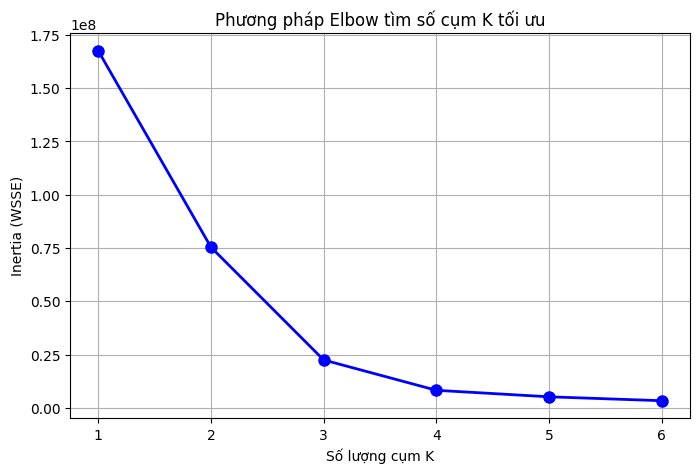

In [5]:
print("Họ tên: Trần Thanh Ngân - MSSV: 6451071048")
print("=" * 60)

import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# 1. Chuẩn bị dữ liệu khách hàng
df = pd.read_excel('Online Retail.xlsx', nrows=5000).dropna(subset=['CustomerID'])
customer_df = df.groupby('CustomerID').agg({'Quantity': 'sum', 'UnitPrice': 'mean'}).reset_index()

# 2. Tính Tổng bình phương khoảng cách (Inertia) cho K từ 1 đến 6
inertias = []
K_range = range(1, 7)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(customer_df[['Quantity', 'UnitPrice']])
    inertias.append(km.inertia_)

# 3. Vẽ biểu đồ Elbow
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
plt.title("Phương pháp Elbow tìm số cụm K tối ưu")
plt.xlabel("Số lượng cụm K")
plt.ylabel("Inertia (WSSE)")
plt.grid(True)
plt.show()

In [6]:
print("Họ tên: Trần Thanh Ngân - MSSV: 6451071048")
print("=" * 60)

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Đọc dữ liệu
df = pd.read_excel('Online Retail.xlsx', nrows=5000).dropna(subset=['CustomerID'])
customer_df = df.groupby('CustomerID').agg({'Quantity': 'sum', 'UnitPrice': 'mean'}).reset_index()

# 2. Tính Silhouette Score cho các giá trị K khác nhau
print("--- ĐÁNH GIÁ SILHOUETTE SCORE CHO CÁC GIÁ TRỊ K ---")
for k in range(2, 6):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(customer_df[['Quantity', 'UnitPrice']])
    score = silhouette_score(customer_df[['Quantity', 'UnitPrice']], labels)
    print(f"Silhouette Score cho K = {k}: {score:.4f}")

Họ tên: Trần Thanh Ngân - MSSV: 6451071048
--- ĐÁNH GIÁ SILHOUETTE SCORE CHO CÁC GIÁ TRỊ K ---
Silhouette Score cho K = 2: 0.9581
Silhouette Score cho K = 3: 0.8954
Silhouette Score cho K = 4: 0.8605
Silhouette Score cho K = 5: 0.7128
